# De l'ACP aux auto-encodeurs profonds avec Keras

Un auto-encodeur comprime son entrée en un code de petite taille (l'encodeur), puis la reconstruit depuis ce code (le décodeur) : sa cible est son entrée elle-même. Ce notebook en entraîne plusieurs sur MNIST (60 000 images d'entraînement et 10 000 de test, des chiffres manuscrits 28 × 28 en niveaux de gris), du plus simple au plus profond :

1. Un auto-encodeur linéaire
2. L'auto-encodeur linéaire face à l'ACP
3. Un auto-encodeur profond
4. L'espace latent
5. La détection d'anomalies
6. La taille du code
7. Pour aller plus loin : un auto-encodeur épars

Chaque partie réutilise les modèles des précédentes ; la dernière est facultative. Pas besoin de GPU : le notebook tourne en une vingtaine de minutes sur un processeur, dont la moitié pour la partie 6, qui entraîne six auto-encodeurs.

(60000, 784) (10000, 784)


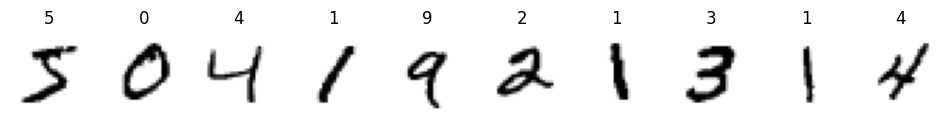

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers
from sklearn.decomposition import PCA

keras.utils.set_random_seed(0)

(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
dim_entree = 28 * 28
# Pixels dans [0, 1], comme la sortie d'une sigmoïde : ni centrés, ni réduits
X_train = X_train.reshape(-1, dim_entree) / 255
X_test = X_test.reshape(-1, dim_entree) / 255
print(X_train.shape, X_test.shape)


def affiche_images(
  *rangees: np.ndarray, titres: list | np.ndarray | None = None
) -> None:
  # Affiche des rangées d'images 28 × 28, une rangée par tableau
  n = len(rangees[0])
  _, axes = plt.subplots(
    len(rangees), n, figsize=(n * 1.2, len(rangees) * 1.3), squeeze=False
  )
  for rangee, images in zip(axes, rangees):
    for ax, image in zip(rangee, images):
      ax.imshow(np.reshape(image, (28, 28)), cmap="gray_r")
      ax.axis("off")
  for ax, titre in zip(axes[0], [] if titres is None else titres):
    ax.set_title(titre)
  plt.show()


affiche_images(X_train[:10], titres=y_train[:10])

## 1. Un auto-encodeur linéaire

Sans fonction d'activation, l'encodeur et le décodeur ne sont que des applications linéaires (plus un biais). Le modèle :

- `encodeur` : une couche `Dense` de `dim_code = 20` unités, sur des entrées de taille `dim_entree` ;
- `decodeur` : une couche `Dense` de `dim_entree` unités, sur des codes de taille `dim_code` ;
- `autoencodeur`, qui enchaîne les deux, compilé avec l'optimiseur Adam et la perte `"mse"`.

Un modèle peut servir de couche à un autre : `encodeur` et `decodeur` restent utilisables seuls, ce que les parties suivantes exploitent.

In [2]:
dim_code = 20
encodeur = keras.Sequential(
  [keras.Input(shape=(dim_entree,)), layers.Dense(dim_code)], name="encodeur"
)
decodeur = keras.Sequential(
  [keras.Input(shape=(dim_code,)), layers.Dense(dim_entree)], name="decodeur"
)
autoencodeur = keras.Sequential([encodeur, decodeur], name="autoencodeur")
autoencodeur.compile(optimizer="adam", loss="mse")
autoencodeur.summary()

Model: "autoencodeur"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encodeur (Sequential)           │ (None, 20)             │        15,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decodeur (Sequential)           │ (None, 784)            │        16,464 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,164 (125.64 KB)

 Trainable params: 32,164 (125.64 KB)

 Non-trainable params: 0 (0.00 B)

### Entraînement

La cible est l'entrée : `fit(X_train, X_train)`. La perte de validation se calcule sur les images de test.

Epoch 1/10
235/235 - 6s - 27ms/step - loss: 0.0488 - val_loss: 0.0301
Epoch 2/10
235/235 - 1s - 3ms/step - loss: 0.0272 - val_loss: 0.0248
Epoch 3/10
235/235 - 1s - 3ms/step - loss: 0.0247 - val_loss: 0.0240
Epoch 4/10
235/235 - 1s - 3ms/step - loss: 0.0244 - val_loss: 0.0238
Epoch 5/10
235/235 - 1s - 3ms/step - loss: 0.0242 - val_loss: 0.0238
Epoch 6/10
235/235 - 1s - 3ms/step - loss: 0.0242 - val_loss: 0.0237
Epoch 7/10
235/235 - 1s - 3ms/step - loss: 0.0241 - val_loss: 0.0237
Epoch 8/10
235/235 - 1s - 3ms/step - loss: 0.0241 - val_loss: 0.0237
Epoch 9/10
235/235 - 1s - 3ms/step - loss: 0.0241 - val_loss: 0.0237
Epoch 10/10
235/235 - 1s - 3ms/step - loss: 0.0241 - val_loss: 0.0236


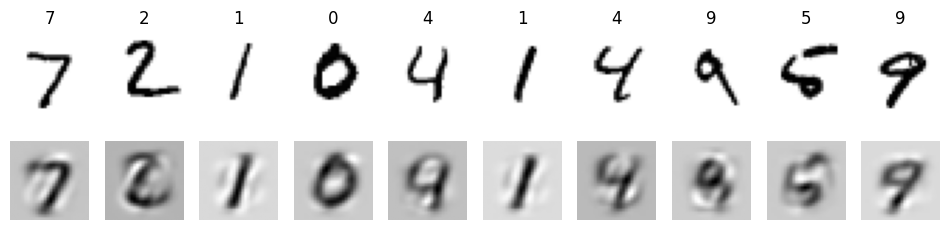

In [3]:
autoencodeur.fit(
  X_train,
  X_train,
  epochs=10,
  batch_size=256,
  validation_data=(X_test, X_test),
  verbose=2,
)
decodeur_lineaire = decodeur  # gardé pour la partie 2
X_test_lineaire = autoencodeur.predict(X_test, verbose=0)
affiche_images(X_test[:10], X_test_lineaire[:10], titres=y_test[:10])

Les reconstructions sont floues, sur un fond gris, mais la plupart des chiffres restent reconnaissables : 20 nombres gardent leur forme générale. Le fond gris vient de la sortie linéaire, qui rend des pixels un peu à côté de 0 partout. Certains chiffres glissent vers un autre, comme le premier 4, qui ressemble à un 9 : l'auto-encodeur linéaire ne garde que les grandes tendances des données.

## 2. L'auto-encodeur linéaire face à l'ACP

La slide « Auto-encodeur linéaire et ACP » l'affirme : entraîné avec la MSE, un auto-encodeur linéaire à code de taille k retrouve le sous-espace des k premières composantes de l'ACP, mais pas ses axes. Vérifions-le en trois mesures :

- une `PCA` à `dim_code` composantes, ajustée sur `X_train`, reconstruit `X_test` : on compare l'erreur quadratique moyenne de sa reconstruction à celle de l'auto-encodeur ;
- les 20 directions du décodeur sont les lignes de son noyau `W` (20 × 784) : pour chacune, on mesure la part de sa norme qui tombe dans le sous-espace de l'ACP (1 : entièrement dedans) ;
- enfin, le plus grand cosinus, en valeur absolue, entre deux directions du décodeur, puis entre deux composantes de l'ACP (0 : orthogonales).

In [4]:
acp = PCA(dim_code).fit(X_train)
X_test_acp = acp.inverse_transform(acp.transform(X_test))
erreur_acp = np.mean((X_test - X_test_acp) ** 2)
erreur_lineaire = np.mean((X_test - X_test_lineaire) ** 2)
print(f"Erreur : ACP {erreur_acp:.4f}, AE linéaire {erreur_lineaire:.4f}")

W = decodeur_lineaire.layers[0].get_weights()[0]  # (20, 784)
part = np.linalg.norm(W @ acp.components_.T, axis=1) / np.linalg.norm(W, axis=1)
print(f"Part dans le sous-espace de l'ACP : de {part.min():.3f} à {part.max():.3f}")


def cosinus_max(V: np.ndarray) -> float:
  V = V / np.linalg.norm(V, axis=1, keepdims=True)
  cosinus = V @ V.T
  return np.abs(cosinus[~np.eye(len(V), dtype=bool)]).max()


print(
  f"Plus grand cosinus : décodeur {cosinus_max(W):.2f}, ACP {cosinus_max(acp.components_):.2f}"
)

Erreur : ACP 0.0235, AE linéaire 0.0236
Part dans le sous-espace de l'ACP : de 0.969 à 1.000
Plus grand cosinus : décodeur 0.23, ACP 0.00


Les deux erreurs sont presque égales : l'auto-encodeur linéaire fait aussi bien que l'ACP, mais pas mieux, puisque l'ACP donne la meilleure reconstruction linéaire possible à 20 dimensions. Ses 20 directions sont presque entièrement dans le sous-espace de l'ACP (à plus de 95 %) : il a trouvé le même sous-espace, aux imprécisions de l'entraînement près. Mais elles ne sont pas orthogonales (le plus grand cosinus vaut environ 0,2, contre 0 pour l'ACP), ni triées par variance expliquée : rien dans la perte ne l'exige. L'ACP donne cette base en plus, et sans entraînement.

## 3. Un auto-encodeur profond

Ajoutons une couche cachée non linéaire de part et d'autre du code, en laissant ouvert le choix de la sortie : `construit_autoencodeur(dim_code, activation_sortie, perte)` rend l'auto-encodeur compilé :

- `encodeur` : une `Dense` de 128 unités, puis une de `dim_code` unités, toutes deux avec l'activation ReLU ;
- `decodeur` : une `Dense` de 128 unités (ReLU), puis la couche de sortie, de `dim_entree` unités et d'activation `activation_sortie` (`None` : sortie linéaire) ;
- l'auto-encodeur, qui enchaîne les deux, compilé avec l'optimiseur Adam et la perte `perte`.

In [5]:
def construit_autoencodeur(
  dim_code: int, activation_sortie: str | None, perte: str
) -> keras.Model:
  encodeur = keras.Sequential(
    [
      keras.Input(shape=(dim_entree,)),
      layers.Dense(128, activation="relu"),
      layers.Dense(dim_code, activation="relu"),
    ],
    name="encodeur",
  )
  decodeur = keras.Sequential(
    [
      keras.Input(shape=(dim_code,)),
      layers.Dense(128, activation="relu"),
      # None : sortie linéaire ; "sigmoid" : sortie dans ]0, 1[
      layers.Dense(dim_entree, activation=activation_sortie),
    ],
    name="decodeur",
  )
  autoencodeur = keras.Sequential([encodeur, decodeur], name="autoencodeur")
  autoencodeur.compile(optimizer="adam", loss=perte)
  return autoencodeur

### Entraînement et comparaison

Deux auto-encodeurs profonds, avec le code de 20 nombres de la partie 1 et 10 epochs chacun : l'un à sortie linéaire et perte `"mse"`, l'autre à sortie sigmoïde et perte `"binary_crossentropy"`, qui traite chaque pixel cible comme une probabilité. Leurs erreurs quadratiques moyennes, la seule mesure commune aux deux pertes, se comparent à celles de l'ACP et de l'auto-encodeur linéaire ; la plage des pixels que chacun rend dit lequel convient à des pixels dans [0, 1].

Sortie linéaire, perte mse : erreur 0.0208, pixels de -0.66 à 1.74
Sortie sigmoid, perte binary_crossentropy : erreur 0.0141, pixels de 0.00 à 1.00
Erreur : ACP 0.0235, AE linéaire 0.0236


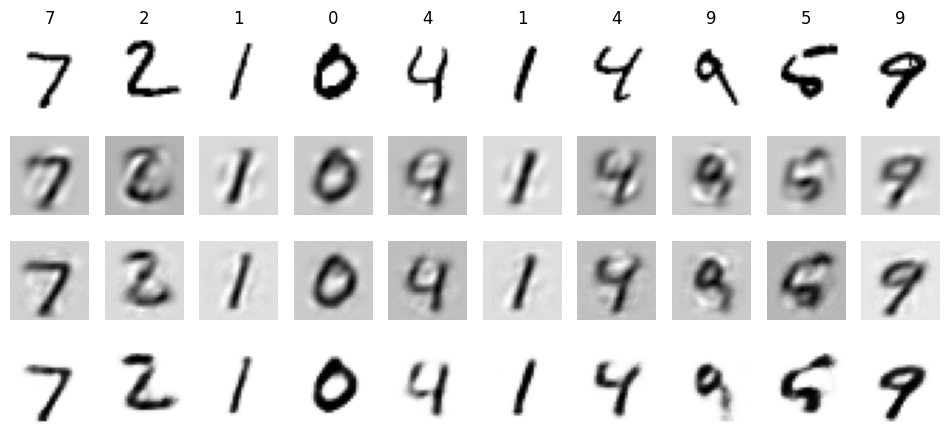

In [6]:
X_test_profond = {}
for activation_sortie, perte in [(None, "mse"), ("sigmoid", "binary_crossentropy")]:
  autoencodeur = construit_autoencodeur(dim_code, activation_sortie, perte)
  autoencodeur.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=256,
    validation_data=(X_test, X_test),
    verbose=0,
  )
  X_test_pred = autoencodeur.predict(X_test, verbose=0)
  X_test_profond[perte] = X_test_pred
  print(
    f"Sortie {activation_sortie or 'linéaire'}, perte {perte} : "
    f"erreur {np.mean((X_test - X_test_pred) ** 2):.4f}, "
    f"pixels de {X_test_pred.min():.2f} à {X_test_pred.max():.2f}"
  )
print(f"Erreur : ACP {erreur_acp:.4f}, AE linéaire {erreur_lineaire:.4f}")
# En haut les originaux, puis l'AE linéaire, puis les AE profonds (MSE, puis BCE)
affiche_images(
  X_test[:10],
  X_test_lineaire[:10],
  X_test_profond["mse"][:10],
  X_test_profond["binary_crossentropy"][:10],
  titres=y_test[:10],
)
# La suite garde le dernier, à sortie sigmoïde, et ses deux moitiés
encodeur, decodeur = autoencodeur.layers

Avec le même code de 20 nombres, l'auto-encodeur profond à sortie sigmoïde reconstruit nettement mieux que l'ACP et que l'auto-encodeur linéaire : ses couches non linéaires suivent des surfaces courbes, hors de portée d'un sous-espace. Celui à sortie linéaire fait à peine mieux que l'ACP : il rend des pixels hors de [0, 1], sous 0 et au-dessus de 1, et un fond gris là où l'image est blanche, des valeurs que la sigmoïde exclut par construction. Pour des pixels dans [0, 1], la sortie sigmoïde s'impose, avec la `binary_crossentropy`, qui traite chaque pixel comme une probabilité. La suite garde cet auto-encodeur, dans `autoencodeur`, `encodeur` et `decodeur`.

## 4. L'espace latent

L'encodeur seul transforme chaque image de test en son code, un point d'un espace à `dim_code` dimensions : l'espace latent.

In [7]:
codes = encodeur.predict(X_test, verbose=0)
print(codes.shape)

(10000, 20)


### Où vivent les codes ?

Le décodeur seul pourrait-il fabriquer de nouveaux chiffres à partir de codes tirés au hasard ? Regardons d'abord où vivent les vrais codes : pour chacune des 20 dimensions, le minimum, la moyenne et le maximum des `codes`, et le nombre de dimensions mortes, nulles pour toutes les images. Puis décodons 10 codes de bruit blanc, tirés uniformément dans [0, 1] sur chaque dimension (en haut), et 10 codes tirés uniformément entre le minimum et le maximum de chaque dimension (en bas).

Min : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Moyenne : [21.6 14.6 12.6 12.6  5.8  8.4  6.8  9.8 11.1 10.8  0.  14.1  0.  13.8
 15.1  7.3 14.1 10.4  8.4  7.6]
Max : [54.  39.4 36.4 38.3 16.5 24.1 20.6 23.1 26.6 33.6  0.  35.9  0.  43.9
 40.9 25.4 34.9 30.3 22.3 20.1]
Dimensions mortes : 2


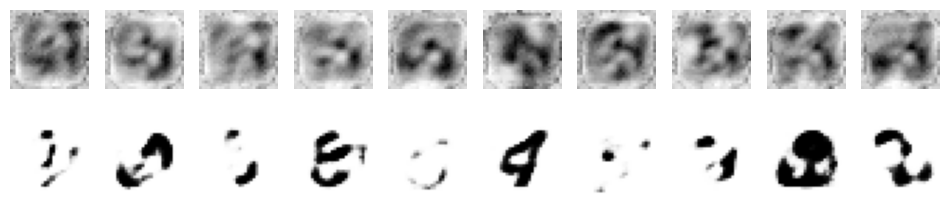

In [8]:
bas, haut = codes.min(axis=0), codes.max(axis=0)
print("Min :", np.round(bas, 1))
print("Moyenne :", np.round(codes.mean(axis=0), 1))
print("Max :", np.round(haut, 1))
print("Dimensions mortes :", int((haut == 0).sum()))

rng = np.random.default_rng(0)
bruit_blanc = rng.uniform(0, 1, size=(10, dim_code))
dans_plage = rng.uniform(bas, haut, size=(10, dim_code))
# En haut le bruit blanc, en bas les codes tirés dans leur plage
affiche_images(
  decodeur.predict(bruit_blanc, verbose=0), decodeur.predict(dans_plage, verbose=0)
)

Les codes ne ressemblent pas à du bruit uniforme dans [0, 1] : la ReLU les rend positifs ou nuls, leur plage change d'une dimension à l'autre et va jusqu'à plusieurs dizaines, et une dimension ou plus peut être morte, nulle pour toutes les images. Le bruit blanc tombe donc dans un coin de l'espace latent, près de l'origine, que le décodeur n'a presque jamais vu : il rend des taches qui se ressemblent toutes. Tirés dans leur plage, les codes ne donnent pas mieux : les vrais codes n'occupent qu'une petite partie de ce pavé, car leurs dimensions sont liées entre elles. Un auto-encodeur compresse, mais ne génère pas : son décodeur ne sait décoder que les codes que produit l'encodeur. L'auto-encodeur variationnel, dans le notebook suivant, impose aux codes une loi connue, $\mathcal{N}(0, I)$, dans laquelle on peut tirer.

### Les centroïdes des chiffres

Les codes ne sont pas dispersés au hasard : ceux d'un même chiffre se regroupent. Le code moyen de chaque chiffre, son centroïde, décodé, en donne une image type.

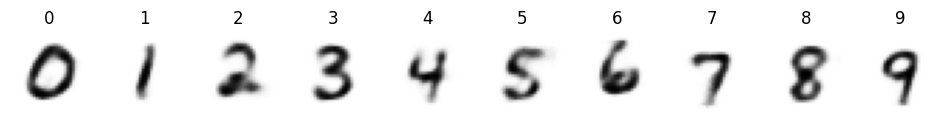

In [9]:
centroides = np.stack([codes[y_test == chiffre].mean(axis=0) for chiffre in range(10)])
affiche_images(decodeur.predict(centroides, verbose=0), titres=list(range(10)))

Chaque centroïde décodé donne un chiffre net et typique, plus lisse que les vrais : la moyenne des codes efface les particularités de chaque écriture.

### Interpoler entre deux centroïdes

Les codes régulièrement espacés sur le segment qui relie deux centroïdes, une fois décodés, montrent comment le décodeur passe d'un chiffre à l'autre. D'autres paires s'essaient en changeant les arguments de `parcours_latent`.

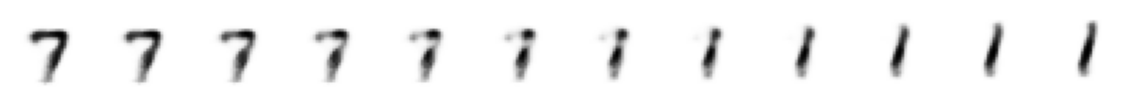

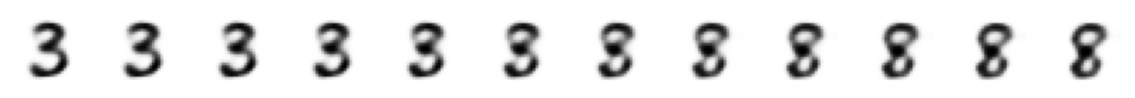

In [10]:
def parcours_latent(debut: int, fin: int, n: int = 12) -> None:
  # n codes régulièrement espacés, du centroïde de debut à celui de fin
  parcours = np.linspace(centroides[debut], centroides[fin], n)
  affiche_images(decodeur.predict(parcours, verbose=0))


parcours_latent(7, 1)
parcours_latent(3, 8)

Le 7 se redresse et perd sa barre pour devenir un 1, le 3 se referme à gauche pour devenir un 8 : d'un centroïde à l'autre, le décodeur passe par des formes intermédiaires, sans saut. Des codes proches se décodent en images proches.

## 5. La détection d'anomalies

Un auto-encodeur reconstruit bien ce qui ressemble à ses exemples d'entraînement, et mal le reste (slide « Détection d'anomalies par erreur de reconstruction »). Celui-ci n'a vu que des chiffres : 1 000 images de vêtements de Fashion-MNIST, dans `X_anomalies`, jouent les anomalies. Le seuil se fixe sur des normaux que le modèle n'a pas appris : les images de test, dont `fit` ne se sert que pour afficher la perte de validation, coupées en deux moitiés, une image sur deux, `X_val` pour fixer le seuil et `X_normal` pour le mettre à l'épreuve (deux moitiés contiguës ne se ressemblent pas assez : les images de MNIST ne sont pas rangées au hasard). Puis :

- l'erreur quadratique moyenne de reconstruction de chaque image, dans `erreurs_val`, `erreurs_normales` et `erreurs_anomalies` ;
- un seuil au quantile à 99 % de `erreurs_val` : 1 % des images de `X_val` le dépassent, et l'on mesure la part des normaux de `X_normal`, puis celle des anomalies, au-delà ;
- les 10 images de `X_normal` les plus mal reconstruites, au-dessus de leur reconstruction, les 10 mieux reconstruites, puis 10 anomalies.

In [11]:
# Les normaux : les images de test, que fit n'a pas apprises, une sur deux de chaque côté
X_val, X_normal = X_test[::2], X_test[1::2]
y_normal = y_test[1::2]
# Les anomalies : 1 000 images de Fashion-MNIST, des vêtements
(X_fashion, _), _ = keras.datasets.fashion_mnist.load_data()
X_anomalies = X_fashion[:1000].reshape(-1, dim_entree) / 255
X_val_pred = autoencodeur.predict(X_val, verbose=0)
X_normal_pred = autoencodeur.predict(X_normal, verbose=0)
X_anomalies_pred = autoencodeur.predict(X_anomalies, verbose=0)

Seuil : 0.0374
Normaux au-delà : 0.8%
Anomalies au-delà : 87.5%
Les normaux les plus mal reconstruits


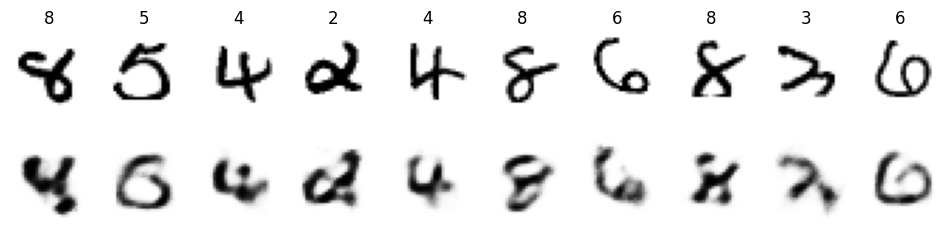

Les mieux reconstruits


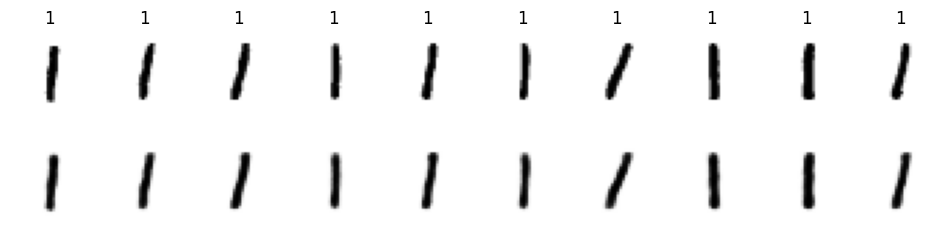

Des anomalies


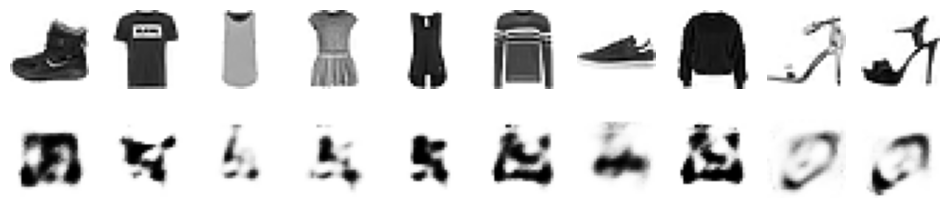

In [12]:
erreurs_val = np.mean((X_val - X_val_pred) ** 2, axis=1)
erreurs_normales = np.mean((X_normal - X_normal_pred) ** 2, axis=1)
erreurs_anomalies = np.mean((X_anomalies - X_anomalies_pred) ** 2, axis=1)
seuil = np.quantile(erreurs_val, 0.99)
print(f"Seuil : {seuil:.4f}")
print(f"Normaux au-delà : {(erreurs_normales > seuil).mean():.1%}")
print(f"Anomalies au-delà : {(erreurs_anomalies > seuil).mean():.1%}")

ordre = np.argsort(erreurs_normales)
pires, meilleurs = ordre[::-1][:10], ordre[:10]
print("Les normaux les plus mal reconstruits")
affiche_images(X_normal[pires], X_normal_pred[pires], titres=y_normal[pires])
print("Les mieux reconstruits")
affiche_images(
  X_normal[meilleurs], X_normal_pred[meilleurs], titres=y_normal[meilleurs]
)
print("Des anomalies")
affiche_images(X_anomalies[:10], X_anomalies_pred[:10])

Environ 1 % des normaux de `X_normal` dépassent le seuil, comme prévu : `X_val` et `X_normal` viennent des mêmes données. La grande majorité des anomalies le dépassent, près de 9 sur 10 : l'auto-encodeur n'a jamais vu de vêtement, et les reconstruit en taches qui tirent vers un chiffre. Le seuil ne les attrape pas toutes : en le baissant, on en attraperait davantage, au prix de plus de fausses alertes. Les normaux les plus mal reconstruits sont des chiffres de forme rare, épais ou mal formés : ils s'éloignent de ce que l'auto-encodeur a vu, et sa reconstruction les ramène vers un chiffre plus courant. Les mieux reconstruits sont surtout des 1 : peu de pixels allumés, une forme simple, donc peu d'erreur. L'erreur dépend donc aussi de la classe : avec un seul seuil, un chiffre compliqué est plus souvent signalé qu'un 1.

## 6. La taille du code

Un code plus grand reconstruit mieux, mais compresse moins (slide « Code sous-complet ou sur-complet »). Pour mesurer ce compromis, la boucle entraîne avec `construit_autoencodeur` un auto-encodeur à sortie sigmoïde et perte `"binary_crossentropy"` pour chaque taille de code de 2, 4, 8, 16, 32 et 64, pendant 10 epochs chacun. Chaque modèle entraîné est gardé dans le dictionnaire `autoencodeurs` (la partie 7 réutilise celui de taille 64), sa dernière perte de validation dans `pertes_val`. La courbe a un axe des abscisses en échelle logarithmique de base 2 ; sous elle, les 10 premières images de test, puis leurs reconstructions par chaque modèle, une rangée par taille de code. Cette cellule prend près de la moitié du temps de la démo.

Code de taille 2 (compression 392x) : perte de validation 0.2015
Code de taille 4 (compression 196x) : perte de validation 0.1803
Code de taille 8 (compression 98x) : perte de validation 0.1383
Code de taille 16 (compression 49x) : perte de validation 0.1112
Code de taille 32 (compression 24x) : perte de validation 0.0924
Code de taille 64 (compression 12x) : perte de validation 0.0823


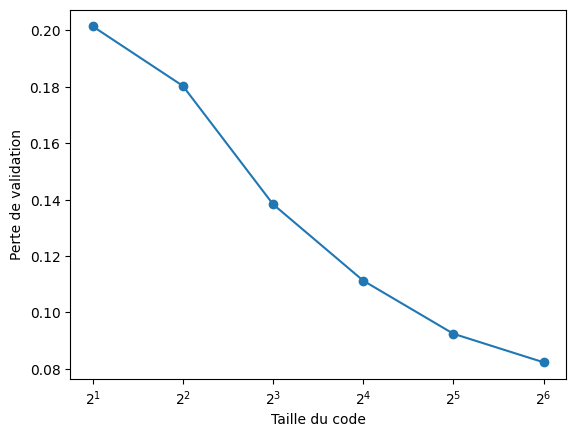

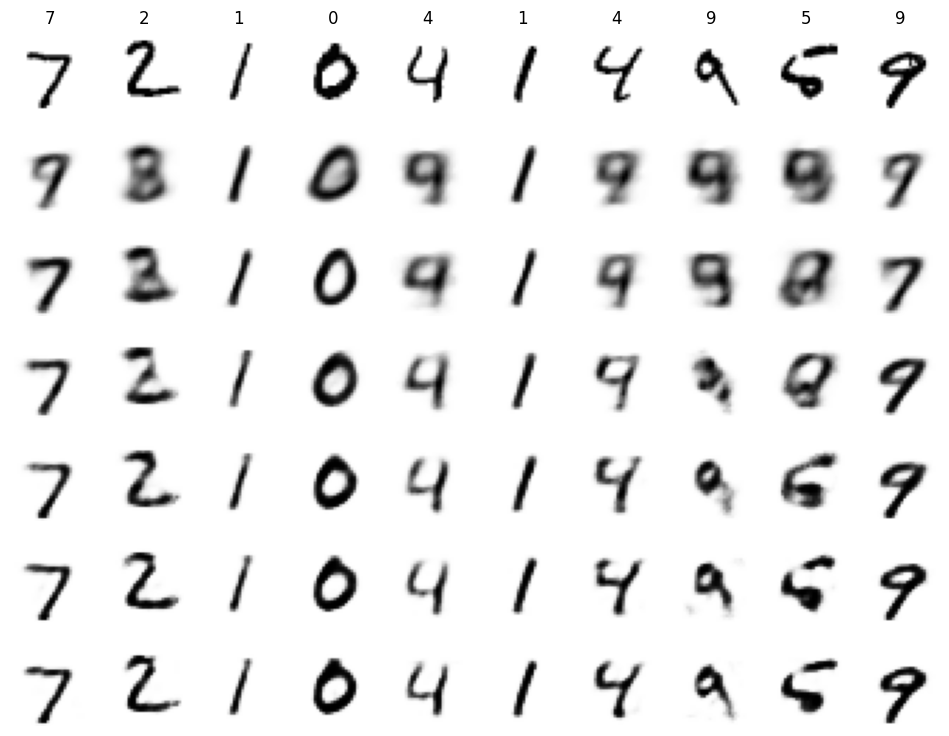

In [13]:
autoencodeurs, pertes_val = {}, {}
for taille in [2, 4, 8, 16, 32, 64]:
  autoencodeurs[taille] = construit_autoencodeur(
    taille, "sigmoid", "binary_crossentropy"
  )
  historique = autoencodeurs[taille].fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=256,
    validation_data=(X_test, X_test),
    verbose=0,
  )
  pertes_val[taille] = historique.history["val_loss"][-1]
  print(
    f"Code de taille {taille} (compression {dim_entree / taille:.0f}x) : "
    f"perte de validation {pertes_val[taille]:.4f}"
  )

plt.plot(list(pertes_val), list(pertes_val.values()), marker="o")
plt.xscale("log", base=2)
plt.xlabel("Taille du code")
plt.ylabel("Perte de validation")
plt.show()

# En haut les originaux, puis une rangée par taille de code, de 2 à 64
reconstructions = [
  keras.ops.convert_to_numpy(modele(X_test[:10])) for modele in autoencodeurs.values()
]
affiche_images(X_test[:10], *reconstructions, titres=y_test[:10])

La perte baisse vite tant que le code est très petit, puis de moins en moins : chaque doublement du code rapporte moins que le précédent. Les images le montrent : avec 2 ou 4 nombres, les reconstructions sont floues et plusieurs chiffres se confondent, un 4 ou un 5 devenant un 9 ; à partir de 16, elles sont nettes. Un code de 16 à 32 dimensions est un bon compromis, soit un taux de compression de 784 / 32 = 24,5 à 784 / 16 = 49 (en nombre de valeurs : le code et les pixels sont tous des flottants).

### Le code à deux dimensions

Avec un code de 2 nombres, l'espace latent de `autoencodeurs[2]` se dessine : chaque image de test y devient un point, coloré selon son chiffre, une étiquette que l'auto-encodeur n'a jamais vue (slide « Espace latent d'un auto-encodeur »). À côté, les mêmes images projetées sur les deux premières composantes de l'ACP, la réduction de dimension linéaire de la partie 2.

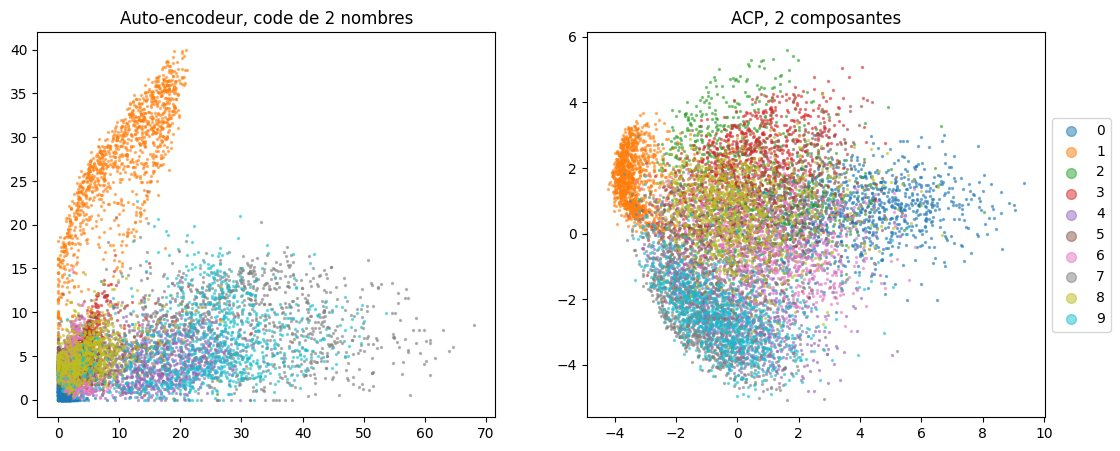

In [14]:
codes_2d = autoencodeurs[2].layers[0].predict(X_test, verbose=0)
acp_2d = PCA(2).fit(X_train).transform(X_test)
_, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, points, titre in [
  (axes[0], codes_2d, "Auto-encodeur, code de 2 nombres"),
  (axes[1], acp_2d, "ACP, 2 composantes"),
]:
  for chiffre in range(10):
    selectionnes = points[y_test == chiffre]
    ax.scatter(selectionnes[:, 0], selectionnes[:, 1], s=2, alpha=0.5, label=chiffre)
  ax.set_title(titre)
axes[1].legend(markerscale=5, loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

Sans jamais voir d'étiquette, l'auto-encodeur isole certains chiffres mieux que l'ACP : les 1, par exemple, y forment une branche à part. Mais la ReLU de son code écrase beaucoup de codes à 0, sur un axe ou sur les deux : les autres chiffres s'entassent près de l'origine, où ils se mêlent plus que dans l'ACP. Les codes laissent aussi de grands vides, où un point pris au hasard ne se décode pas en un chiffre. Un code sans activation, comme celui de la slide « Espace latent d'un auto-encodeur », s'étale mieux.

## 7. Pour aller plus loin : un auto-encodeur épars

Un auto-encodeur épars a un code large, mais une pénalité sur ses activations n'en laisse que peu actives pour chaque image. `autoencodeur_epars` est l'auto-encodeur profond avec un code de 64 unités, dont la couche ajoute à la perte une pénalité L1 de coefficient 4e-6 sur ses activations (`activity_regularizer`) : 4e-6 fois la somme des valeurs absolues de ses 64 sorties, sur toutes les images du lot. Keras ne divise pas cette somme par la taille du lot : pour des lots de 256 images, 4e-6 revient à 1e-3 par image. Il s'entraîne 10 epochs, comme ceux de la partie 6.

On le compare à l'auto-encodeur de la partie 6 à code de 64 unités, `autoencodeurs[64]` : le nombre moyen d'unités actives (> 0) du code par image de test, le nombre d'unités jamais actives, et l'erreur quadratique moyenne de reconstruction.

In [15]:
encodeur_epars = keras.Sequential(
  [
    keras.Input(shape=(dim_entree,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(
      64, activation="relu", activity_regularizer=keras.regularizers.L1(4e-6)
    ),
  ],
  name="encodeur_epars",
)
decodeur_epars = keras.Sequential(
  [
    keras.Input(shape=(64,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(dim_entree, activation="sigmoid"),
  ],
  name="decodeur_epars",
)
autoencodeur_epars = keras.Sequential(
  [encodeur_epars, decodeur_epars], name="autoencodeur_epars"
)
autoencodeur_epars.compile(optimizer="adam", loss="binary_crossentropy")
autoencodeur_epars.fit(
  X_train,
  X_train,
  epochs=10,
  batch_size=256,
  validation_data=(X_test, X_test),
  verbose=0,
)

for nom, modele in [("Sans pénalité", autoencodeurs[64]), ("L1", autoencodeur_epars)]:
  codes = modele.layers[0].predict(X_test, verbose=0)
  erreur = np.mean((X_test - modele.predict(X_test, verbose=0)) ** 2)
  print(
    f"{nom} : {(codes > 0).sum(axis=1).mean():.1f} unités actives par image sur 64, "
    f"{(codes.max(axis=0) == 0).sum()} jamais actives, erreur {erreur:.4f}"
  )

Sans pénalité : 57.9 unités actives par image sur 64, 4 jamais actives, erreur 0.0068
L1 : 24.8 unités actives par image sur 64, 29 jamais actives, erreur 0.0118


Avec la pénalité, chaque image n'active plus qu'une vingtaine d'unités du code au lieu d'une cinquantaine, et près de la moitié des unités ne s'activent jamais : la pénalité éteint les unités les moins utiles. La parcimonie se paie en reconstruction, dont l'erreur double presque. Le coefficient règle ce compromis : à 1e-6, l'effet est bien plus faible, une quarantaine d'unités restant actives ; à 1e-4, le code s'éteint. Dans un code épars, chaque unité active porte un motif qu'on peut regarder seul : c'est ce qui sert à interpréter les représentations des grands modèles de langage.

## À retenir

- Un auto-encodeur apprend à reconstruire son entrée à travers un code étroit : `fit(X, X)`, sans étiquette.
- Linéaire et entraîné avec la MSE, il retrouve le sous-espace de l'ACP, mais pas ses axes orthogonaux et triés : l'ACP donne ce résultat en mieux, sans entraînement.
- Des couches non linéaires reconstruisent nettement mieux avec le même code de 20 nombres ; pour des pixels dans [0, 1], une sortie sigmoïde et la `binary_crossentropy`.
- Les codes n'occupent qu'une petite région de l'espace latent : décoder un code tiré au hasard ne donne pas un chiffre. Pour générer, il faut un auto-encodeur variationnel (démo suivante).
- L'erreur de reconstruction signale les images inhabituelles : un seuil fixé sur des normaux tenus à l'écart de l'entraînement détecte la plupart des anomalies, au prix de 1 % de fausses alertes. Elle dépend aussi de la classe : un seul seuil signale plus souvent les chiffres compliqués.
- La taille du code règle le compromis entre compression et qualité ; une pénalité L1 rend le code épars, au prix d'une reconstruction moins bonne.